# Merging the two Sarasota chlorophyll-a datasets

Issue #14 — Preprocess chlorophyll and wind data from 09/15.

Combines `ChlorophyllaConcentrationSarasota.csv` (**DS1**, 2020-06 → 2026-09) and `ChlorophyllaConcentrationSarasota_Dataset2.csv` (**DS2**, 2010-01 → 2022-05) into one daily chlorophyll table on DS1's grid, covering 2010–2026.

Every rule below comes from [`compare_chlorophyll_datasets.ipynb`](compare_chlorophyll_datasets.ipynb); the section numbers in brackets point to the evidence.

| Stage | What happens |
|---|---|
| 1. Clean | longitude to −180..180, drop invalid low values, flag limit values, drop land cells, flag coastal cells, add `log_chl` |
| 2. Match grids | each DS1 water cell gets its nearest DS2 pixel by distance |
| 3. Adjust DS2 | quantile mapping fitted on the 2020–2022 overlap, so DS2 reads like DS1 at every chlorophyll level |
| 4. Combine | DS1 wherever it has data, adjusted DS2 elsewhere; checks; save to Parquet |

**Output:** `data/processed/chlorophyll_merged.parquet`, one row per valid observation: `date, latitude, longitude, chlor_a, log_chl, chlor_a_raw, source, chl_at_limit, coastal`. A missing row means "no observation that day" (cloud, glint, etc.).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.spatial import cKDTree

DATA = Path("../data")
DS1_PATH = DATA / "ChlorophyllaConcentrationSarasota.csv"
DS2_PATH = DATA / "ChlorophyllaConcentrationSarasota_Dataset2.csv"
OUT_PATH = DATA / "processed" / "chlorophyll_merged.parquet"

OVERLAP_START, OVERLAP_END = pd.Timestamp("2020-06-15"), pd.Timestamp("2022-05-31")
LOW_LIMIT = 0.01     # below this: outside the algorithm's valid range -> NaN (2.5)
HIGH_LIMIT = 99      # at/above this: at the product's upper limit -> keep, flag (2.5)
COASTAL_KM = 10      # water cells this close to land are flagged as coastal (2.4)
MATCH_KM = 3.5       # max distance when matching a DS1 cell to a DS2 pixel (2.1, 2.3)

def to_km(lat, lon):
    # degrees -> km; longitude degrees are shorter at Sarasota's latitude (~27.3 N)
    return np.c_[np.asarray(lat) * 111, np.asarray(lon) * 111 * np.cos(np.radians(27.3))]

## Stage 1 — Clean each dataset

- Skip the units row (row 2), drop `altitude`, convert `time` to a date.
- `longitude − 360`, so it matches habsos and CHIRPS (2.2).
- `chlor_a < 0.01` → NaN; only DS1 has these (2.5).
- `chl_at_limit = 1` where `chlor_a ≥ 99`; the value is **kept** (2.5).
- Cells with no valid value on any day are land (2.4) and are dropped.
- Only valid observations are kept; NaN rows carry no information once the land cells are known.
- No IQR, winsorizing or mean/median filling (2.4, 2.5).

In [2]:
def load_clean(path, name):
    df = pd.read_csv(path, skiprows=[1], usecols=["time", "latitude", "longitude", "chlor_a"])
    df["date"] = pd.to_datetime(df["time"]).dt.tz_localize(None).dt.normalize()
    df["longitude"] = df["longitude"] - 360

    n_low = int((df.chlor_a < LOW_LIMIT).sum())
    df.loc[df.chlor_a < LOW_LIMIT, "chlor_a"] = np.nan

    cells = df.groupby(["latitude", "longitude"]).chlor_a.count().rename("n_valid").reset_index()
    land = cells[cells.n_valid == 0]
    water = cells[cells.n_valid > 0].copy()
    water["km_to_land"] = cKDTree(to_km(land.latitude, land.longitude)).query(
        to_km(water.latitude, water.longitude))[0]

    obs = df.dropna(subset=["chlor_a"])[["date", "latitude", "longitude", "chlor_a"]].reset_index(drop=True)
    obs["chl_at_limit"] = (obs.chlor_a >= HIGH_LIMIT).astype("int8")
    obs["log_chl"] = np.log10(obs.chlor_a)

    print(f"{name}: {len(df):,} rows -> {len(obs):,} valid observations | "
          f"{len(water)} water cells, {len(land)} land cells dropped | "
          f"{n_low} values < {LOW_LIMIT} set to NaN | {int(obs.chl_at_limit.sum())} flagged at limit")
    return obs, water

ds1, water1 = load_clean(DS1_PATH, "DS1")
ds2, water2 = load_clean(DS2_PATH, "DS2")

# the final grid is DS1's water cells; coastal flag lives on that grid
water1["coastal"] = (water1.km_to_land <= COASTAL_KM).astype("int8")
print(f"Coastal cells (within {COASTAL_KM} km of land): {water1.coastal.sum()} of {len(water1)}")

DS1: 4,202,008 rows -> 1,039,492 valid observations | 1328 water cells, 558 land cells dropped | 20 values < 0.01 set to NaN | 10 flagged at limit


DS2: 7,010,094 rows -> 1,346,118 valid observations | 989 water cells, 565 land cells dropped | 0 values < 0.01 set to NaN | 10 flagged at limit
Coastal cells (within 10 km of land): 239 of 1328


## Stage 2 — Put DS2 on DS1's grid

For every DS1 water cell, find the **nearest DS2 water pixel by distance** and copy its values (2.1, 2.3). No rounding: DS1's grid points sit halfway between multiples of 0.0375 and rounding collides.

- Each DS1 cell gets at most one DS2 partner, so there is never more than one DS2 value per cell per day.
- DS2 pixels are bigger, so one DS2 pixel can feed two neighbouring DS1 cells. No values are invented; the coarser picture is laid onto the finer grid.
- Matches further than `MATCH_KM` (3.5 km) are dropped. This affects edge strips, and bay cells where DS2 has no water pixel nearby (2.4 map).

In [3]:
dist, idx = cKDTree(to_km(water2.latitude, water2.longitude)).query(to_km(water1.latitude, water1.longitude))
grid_map = water1[["latitude", "longitude"]].assign(
    lat_ds2=water2.latitude.values[idx], lon_ds2=water2.longitude.values[idx], dist_km=dist)
grid_map = grid_map[grid_map.dist_km <= MATCH_KM]

ds2_on1 = (ds2.rename(columns={"latitude": "lat_ds2", "longitude": "lon_ds2"})
              .merge(grid_map, on=["lat_ds2", "lon_ds2"])
              .drop(columns=["lat_ds2", "lon_ds2", "dist_km"]))

print(f"DS1 water cells with a DS2 partner: {len(grid_map)} of {len(water1)} "
      f"(median distance {grid_map.dist_km.median():.1f} km)")
print(f"DS2 pixels used: {grid_map[['lat_ds2', 'lon_ds2']].drop_duplicates().shape[0]} of {len(water2)} water pixels")
print(f"DS2 observations on DS1 grid: {len(ds2_on1):,}  "
      f"(duplicates per cell-day: {ds2_on1.duplicated(['date', 'latitude', 'longitude']).sum()})")

DS1 water cells with a DS2 partner: 1205 of 1328 (median distance 1.8 km)
DS2 pixels used: 933 of 989 water pixels
DS2 observations on DS1 grid: 1,627,087  (duplicates per cell-day: 0)


## Stage 3 — Adjust DS2 to read like DS1

DS1 reads ~8% lower than DS2 on average, but the gap is much larger at bloom levels and shifts with the season (2.3). A single factor would leave pre-2020 blooms too high, so DS2 is adjusted with **quantile mapping**:

1. Take every cell-day where **both** datasets have a value (the 2020–2022 overlap), in `log_chl`, leaving out limit values.
2. For each percentile 1 … 99, note DS2's value and DS1's value. This is the translation table.
3. Translate each DS2 value by interpolating in that table. Beyond the 1st/99th percentile, the end offset is carried on, so extreme values are shifted rather than extrapolated.

**Honest check first:** fit the table on overlap year 1 (Jun 2020 – May 2021) and test it on year 2 (Jun 2021 – May 2022), which it has not seen.

*Look up:* "quantile mapping", "CDF matching satellite", "sensor intercalibration".

In [4]:
pairs = ds1.merge(ds2_on1, on=["date", "latitude", "longitude"], suffixes=("_ds1", "_ds2"))
pairs = pairs[(pairs.chl_at_limit_ds1 == 0) & (pairs.chl_at_limit_ds2 == 0)]
print(f"Matched pixel-days in the overlap: {len(pairs):,}")

PCTS = np.linspace(0.01, 0.99, 99)

def fit_qmap(p):
    return np.quantile(p.log_chl_ds2, PCTS), np.quantile(p.log_chl_ds1, PCTS)

def apply_qmap(x, qmap):
    q2, q1 = qmap
    x = np.asarray(x)
    y = np.interp(x, q2, q1)
    y = np.where(x < q2[0], x + (q1[0] - q2[0]), y)
    y = np.where(x > q2[-1], x + (q1[-1] - q2[-1]), y)
    return y

year1 = pairs[pairs.date < "2021-06-01"]
year2 = pairs[pairs.date >= "2021-06-01"].copy()
qmap_test = fit_qmap(year1)
year2["log_ds2_adj"] = apply_qmap(year2.log_chl_ds2, qmap_test)
print(f"Fit on year 1: {len(year1):,} pairs | tested on year 2: {len(year2):,} pairs")

Matched pixel-days in the overlap: 147,146
Fit on year 1: 68,387 pairs | tested on year 2: 78,759 pairs


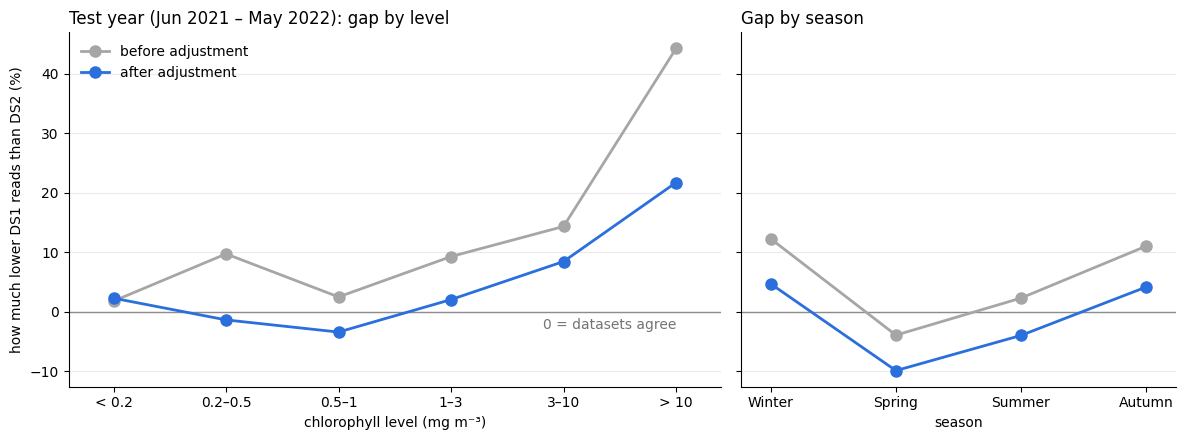

Overall gap on the test year: before 7.3%  ->  after 0.1%


In [5]:
LEVELS = [0, 0.2, 0.5, 1, 3, 10, 100]
LABELS = ["< 0.2", "0.2–0.5", "0.5–1", "1–3", "3–10", "> 10"]
SEASON = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
          6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"}

def pct_lower(log_a, log_b):
    # how much lower a reads than b, in %, from the median log difference
    return (1 - 10 ** np.median(log_a - log_b)) * 100

def gap_table(p, ds2_col):
    level = pd.cut(10 ** ((p.log_chl_ds1 + p[ds2_col]) / 2), LEVELS, labels=LABELS)  # average of both
    season = pd.Categorical(p.date.dt.month.map(SEASON), ["Winter", "Spring", "Summer", "Autumn"], ordered=True)
    g = lambda d: pct_lower(d.log_chl_ds1, d[ds2_col])
    return (p.groupby(level, observed=True).apply(g, include_groups=False),
            p.groupby(season, observed=True).apply(g, include_groups=False),
            g(p))

before_lvl, before_sea, before_all = gap_table(year2, "log_chl_ds2")
after_lvl, after_sea, after_all = gap_table(year2, "log_ds2_adj")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True, gridspec_kw={"width_ratios": [3, 2]})
for ax, before, after, xlabel in [(axes[0], before_lvl, after_lvl, "chlorophyll level (mg m⁻³)"),
                                  (axes[1], before_sea, after_sea, "season")]:
    x = range(len(before))
    ax.axhline(0, color="0.55", lw=1)
    ax.plot(x, before.values, "-o", color="0.65", lw=2, ms=8, label="before adjustment")
    ax.plot(x, after.values, "-o", color="#2a6fdb", lw=2, ms=8, label="after adjustment")
    ax.set_xticks(list(x), before.index.astype(str))
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", color="0.92"); ax.spines[["top", "right"]].set_visible(False); ax.margins(x=0.08)
axes[0].set_ylabel("how much lower DS1 reads than DS2 (%)")
axes[0].set_title("Test year (Jun 2021 – May 2022): gap by level", loc="left")
axes[1].set_title("Gap by season", loc="left")
axes[0].text(len(before_lvl) - 1, -1, "0 = datasets agree", color="0.45", va="top", ha="right")
axes[0].legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

print(f"Overall gap on the test year: before {before_all:.1f}%  ->  after {after_all:.1f}%")

**Reading the check:** the grey line is the raw gap, the blue line is the gap after applying a table fitted on the *other* year, so this is data the adjustment has not seen.

- **Overall and for typical water (up to ~3 mg m⁻³) the gap is essentially closed** (overall ~7% → ~0%).
- **At bloom level (> 10 mg m⁻³) it is roughly halved but not closed**: adjusted DS2 still reads higher than DS1 there.
- **By season it over-corrects in spring** (DS2 now reads lower than DS1) and under-corrects in winter, because one year-round table averages over the seasons.

Now fit the final table on the **whole** overlap and apply it to all of DS2:

In [6]:
qmap = fit_qmap(pairs)

ds2_on1["chlor_a_raw"] = ds2_on1["chlor_a"]
ds2_on1["log_chl"] = apply_qmap(ds2_on1["log_chl"], qmap)
ds2_on1["chlor_a"] = 10 ** ds2_on1["log_chl"]

translation = pd.DataFrame({"percentile": [10, 50, 90, 99],
                            "DS2 (mg m⁻³)": 10 ** np.interp([0.10, 0.50, 0.90, 0.99], PCTS, qmap[0]),
                            "becomes (mg m⁻³)": 10 ** np.interp([0.10, 0.50, 0.90, 0.99], PCTS, qmap[1])})
translation["change (%)"] = (translation["becomes (mg m⁻³)"] / translation["DS2 (mg m⁻³)"] - 1) * 100
translation.round(2)

,percentile,DS2 (mg m⁻³),becomes (mg m⁻³),change (%)
0,10,0.18,0.18,-2.29
1,50,0.50,0.47,-5.51
2,90,3.01,2.73,-9.48
3,99,18.97,11.06,-41.71


## Stage 4 — Combine

| Period | Value used | `source` |
|---|---|---|
| 2010-01-01 → 2020-06-14 | adjusted DS2 | `ds2_adj` |
| 2020-06-15 → 2022-05-31 | DS1; adjusted DS2 only where DS1 has no value that day | `ds1` / `ds2_adj` |
| 2022-06-01 → 2026-09-05 | DS1 | `ds1` |

In [7]:
d1 = ds1.assign(chlor_a_raw=ds1.chlor_a, source="ds1")

# adjusted DS2 only where DS1 has no value for that cell and day
d2 = ds2_on1.merge(d1[["date", "latitude", "longitude"]], on=["date", "latitude", "longitude"],
                   how="left", indicator=True)
d2 = d2[d2["_merge"] == "left_only"].drop(columns="_merge").assign(source="ds2_adj")

cols = ["date", "latitude", "longitude", "chlor_a", "log_chl", "chlor_a_raw", "source", "chl_at_limit"]
merged = (pd.concat([d1[cols], d2[cols]], ignore_index=True)
            .merge(water1[["latitude", "longitude", "coastal"]], on=["latitude", "longitude"], how="left")
            .sort_values(["date", "latitude", "longitude"], ignore_index=True))
merged["source"] = merged["source"].astype("category")
for c in ["chlor_a", "log_chl", "chlor_a_raw"]:
    merged[c] = merged[c].astype("float32")

merged.head()

,date,latitude,longitude,chlor_a,log_chl,chlor_a_raw,source,chl_at_limit,coastal
0,2010-01-02,26.49375,-83.00625,0.734392,-0.134072,0.780984,ds2_adj,0,0
1,2010-01-02,26.49375,-82.96875,0.734391,-0.134073,0.780983,ds2_adj,0,0
2,2010-01-02,26.49375,-82.93125,0.769303,-0.113903,0.821875,ds2_adj,0,0
3,2010-01-02,26.49375,-82.89375,0.789905,-0.102425,0.845540,ds2_adj,0,0
4,2010-01-02,26.49375,-82.85625,0.826479,-0.082768,0.890127,ds2_adj,0,0


### Checks

In [8]:
period = pd.cut(merged.date, [pd.Timestamp("2009-12-31"), OVERLAP_START - pd.Timedelta(days=1), OVERLAP_END, pd.Timestamp("2027-01-01")],
                labels=["2010 → 2020-06-14", "overlap", "2022-06 → 2026"])
checks = {
    "rows": f"{len(merged):,}",
    "duplicate (date, lat, lon)": int(merged.duplicated(["date", "latitude", "longitude"]).sum()),
    "missing values in any column": int(merged.isna().sum().sum()),
    "date range": f"{merged.date.min().date()} → {merged.date.max().date()}",
    "grid cells": merged[["latitude", "longitude"]].drop_duplicates().shape[0],
    "longitude range": f"{merged.longitude.min():.3f} → {merged.longitude.max():.3f}",
    "values at limit (flagged)": int(merged.chl_at_limit.sum()),
    "rows in coastal cells": f"{merged.coastal.mean():.0%}",
}
display(pd.Series(checks, name="value").to_frame())
pd.crosstab(period, merged.source, margins=True)

,value
rows,"2,519,433"
"duplicate (date, lat, lon)",0
missing values in any column,0
date range,2010-01-02 → 2026-09-05
grid cells,1328
longitude range,-83.494 → -81.806
values at limit (flagged),24
rows in coastal cells,6%


source,ds1,ds2_adj,All
date,,,
2010 → 2020-06-14,0,1379929,1379929
overlap,313358,100012,413370
2022-06 → 2026,726134,0,726134
All,1039492,1479941,2519433


**No step at the switch-overs.** Monthly median chlorophyll across the area, 2018–2024. The grey dashed line is what stacking the *unadjusted* DS2 would give. Vertical lines mark where DS1 starts (2020-06) and where DS2 ends (2022-05).

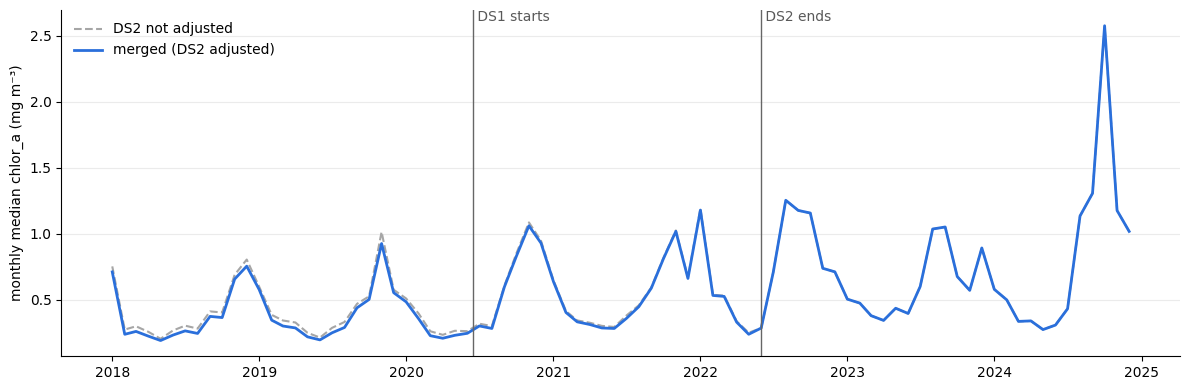

In [9]:
win = merged[(merged.date >= "2018-01-01") & (merged.date < "2025-01-01")]
monthly = win.groupby(win.date.dt.to_period("M")).log_chl.median()
raw_stack = np.log10(np.where(win.source == "ds2_adj", win.chlor_a_raw, win.chlor_a))
monthly_raw = pd.Series(raw_stack, index=win.index).groupby(win.date.dt.to_period("M")).median()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(monthly_raw.index.to_timestamp(), 10 ** monthly_raw.values, color="0.65", lw=1.5, ls="--", label="DS2 not adjusted")
ax.plot(monthly.index.to_timestamp(), 10 ** monthly.values, color="#2a6fdb", lw=2, label="merged (DS2 adjusted)")
for d, txt in [(OVERLAP_START, "DS1 starts"), (OVERLAP_END, "DS2 ends")]:
    ax.axvline(d, color="0.4", lw=1)
    ax.text(d, ax.get_ylim()[1], " " + txt, va="top", color="0.35")
ax.set_ylabel("monthly median chlor_a (mg m⁻³)")
ax.grid(axis="y", color="0.92"); ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

*Caveat:* the monthly median mixes whichever cells have data that month, so it wobbles with cloud cover and with DS1 seeing more bay cells than DS2. Look for a sudden jump exactly at the vertical lines, not for a perfectly smooth line.

## Save

In [10]:
OUT_PATH.parent.mkdir(parents=True, exist_ok=True)
merged.to_parquet(OUT_PATH, index=False)
print(f"Saved {len(merged):,} rows to {OUT_PATH} ({OUT_PATH.stat().st_size / 1e6:.1f} MB)")

Saved 2,519,433 rows to ..\data\processed\chlorophyll_merged.parquet (35.4 MB)


## Columns

| Column | Meaning |
|---|---|
| `date` | day of observation |
| `latitude`, `longitude` | DS1 grid cell centre; longitude in −180..180 |
| `chlor_a` | chlorophyll-a (mg m⁻³) on DS1's scale; for `ds2_adj` rows this is the adjusted value |
| `log_chl` | `log10(chlor_a)`; use this for scaling, correlations and as a model feature (2.5) |
| `chlor_a_raw` | the value as delivered, before adjustment |
| `source` | `ds1` or `ds2_adj` |
| `chl_at_limit` | 1 if the raw value was ≥ 99 mg m⁻³ (product's upper limit; exact value uncertain) |
| `coastal` | 1 if the cell is within 10 km of land; coastal cells have data far less often (2.4) |

## Known limitations

1. **Bay cells before 2020 are mostly empty.** DS2 rarely has data inside Tampa Bay, Sarasota Bay and Charlotte Harbor (2.4), and some bay cells have no DS2 pixel within 3.5 km at all.
2. **Bloom-level values before 2020 are still somewhat too high.** On the test year the bloom-level gap was roughly halved, not closed. Quantile mapping matches the overall distributions; it does not force each pair to agree. Options to try: a per-season table, or a paired calibration (median DS1 value for each DS2 level). Treat `ds2_adj` bloom values with care, and keep `source` as a model feature so the model can tell the periods apart.
3. **One year-round table.** The check shows a remaining seasonal gap (over-corrected in spring, under-corrected in winter); one table per season is the obvious next step.
4. **Gaps may be biased toward blooms.** Quality masks can remove dense-bloom pixels more often than clear water (2.4), so "no row" is not the same as "low chlorophyll".
5. **Product identity unconfirmed.** Which exact satellite products DS1 and DS2 are has not been confirmed with the data provider.